# Preparación: imagen generada con IA

Genera una imagen con un generador de IA gratuito (ej. Bing Image Creator). Usa tu creatividad. **Requisito:** la imagen debe tener dimensiones 1024x1024x3.

Guarda la imagen generada como `../images/mi_imagen_original.png`. Si no es cuadrada, este notebook la recorta al centro, la redimensiona a 1024x1024 y guarda el resultado como `../images/mi_imagen.png`, que usan los demás puntos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from skimage.metrics import structural_similarity as ssim
from skimage.color import rgb2ycbcr, ycbcr2rgb, rgb2yiq, yiq2rgb

import sys
sys.path.append("..")
from colorspaces import rgb_to_cmy, cmy_to_rgb, rgb_to_cmyk, cmyk_to_rgb, rgb_to_hsi, hsi_to_rgb


## Prompt e imagen usada

Incorpora aquí el texto (prompt) usado para generar la imagen.

(832, 1248, 3) uint8
(1024, 1024, 3) uint8


(np.float64(-0.5), np.float64(1023.5), np.float64(1023.5), np.float64(-0.5))

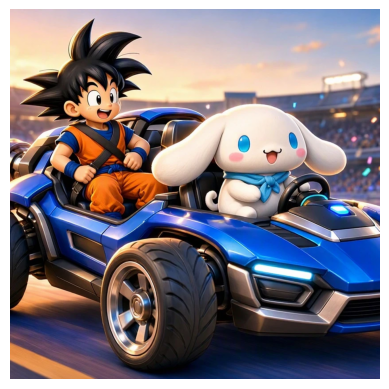

In [2]:
img_original = np.array(Image.open("../images/mi_imagen_original.png").convert("RGB"))
print(img_original.shape, img_original.dtype)

alto, ancho = img_original.shape[:2]
lado = min(alto, ancho)
y0 = (alto - lado) // 2
x0 = (ancho - lado) // 2
cuadrada = img_original[y0:y0 + lado, x0:x0 + lado, :]

img = cv2.resize(cuadrada, (1024, 1024), interpolation=cv2.INTER_CUBIC)
Image.fromarray(img).save("../images/mi_imagen.png")
assert img.shape == (1024, 1024, 3), img.shape
print(img.shape, img.dtype)

plt.figure()
plt.imshow(img)
plt.axis("off")


## Validación de conversiones entre espacios de color (no calificada)

Paso 1: cargar una imagen RGB. Paso 2: convertirla a otro espacio (HSI, CMY, CMYK, YCbCr, YIQ). Paso 3: convertir de vuelta a RGB. Paso 4: SSIM entre el resultado y la imagen original (debe ser 1).

In [3]:
def vuelta_skimage(convertir):
    return lambda x: np.clip(np.round(convertir(x) * 255), 0, 255).astype(np.uint8)

conversiones = {
    "CMY": (rgb_to_cmy, cmy_to_rgb),
    "CMYK": (rgb_to_cmyk, cmyk_to_rgb),
    "HSI": (rgb_to_hsi, hsi_to_rgb),
    "YCbCr": (rgb2ycbcr, vuelta_skimage(ycbcr2rgb)),
    "YIQ": (rgb2yiq, vuelta_skimage(yiq2rgb)),
}

for nombre, (ida, vuelta) in conversiones.items():
    reconstruida = vuelta(ida(img))
    print(f"{nombre}: SSIM = {ssim(reconstruida, img, channel_axis=2, data_range=255):.4f}")


CMY: SSIM = 1.0000


CMYK: SSIM = 1.0000


HSI: SSIM = 1.0000


YCbCr: SSIM = 1.0000


YIQ: SSIM = 1.0000
